<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/JS13/praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 2: Klasifikasi Data Iris Menggunakan Keras dan TensorFlow

Pada praktikum ini kita akan menggunakan library [Keras](https://keras.io/) untuk menggunakan JST. Keras adalah API tingkat tinggi untuk membangun JST dengan mudah, sedangkan TensorFlow adalah framework yang mendukung Keras.

### Langkah Praktikum:
1. Import library.
2. Load dataset.
3. Bangun model.
4. Kompilasi dan latih model.
5. Evaluasi hasil.

### Langkah 1 & 2: Import Library dan Load Dataset Iris
Memuat dataset bunga Iris, melakukan One-Hot Encoding pada label target, serta membagi data menjadi data latih (*training*) sebesar 80% dan data uji (*testing*) sebesar 20%.

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf
import pandas as pd
import numpy as np

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
try:
    encoder = OneHotEncoder(sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(sparse=False)
y = encoder.fit_transform(y)

# Split data (test_size = 0.2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Informasi Dataset Iris:")
print(f"Jumlah data latih (X_train) : {X_train.shape[0]} sampel")
print(f"Jumlah data uji (X_test)   : {X_test.shape[0]} sampel")
print(f"Jumlah fitur input         : {X.shape[1]} (Sepal Length, Sepal Width, Petal Length, Petal Width)")
print(f"Jumlah kelas output        : {y.shape[1]} (Setosa, Versicolor, Virginica)")

Informasi Dataset Iris:
Jumlah data latih (X_train) : 120 sampel
Jumlah data uji (X_test)   : 30 sampel
Jumlah fitur input         : 4 (Sepal Length, Sepal Width, Petal Length, Petal Width)
Jumlah kelas output        : 3 (Setosa, Versicolor, Virginica)


### Langkah 3: Bangun Model JST (Konfigurasi Awal)
Membangun arsitektur Sequential model:
- Hidden Layer 1: 10 neuron, aktivasi ReLU, input_shape=(4,)
- Hidden Layer 2: 8 neuron, aktivasi ReLU
- Output Layer: 3 neuron, aktivasi Softmax (untuk klasifikasi multi-kelas)

In [2]:
# Bangun model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model.summary()

c:\laragon\www\Machine_learning\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

### Langkah 4: Kompilasi dan Latih Model
Kompilasi model dengan optimizer `adam`, loss function `categorical_crossentropy`, dan metrik `accuracy`. Model dilatih sebanyak 50 epoch dengan batch size 8.

In [3]:
# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
history_awal = model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=1)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3250 - loss: 2.3139   
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3250 - loss: 1.6100 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5000 - loss: 1.2135 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 1.0127 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.8635 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.7680 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.7013 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.6574 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6750 - loss: 0.6208 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6917 - loss: 0.5941 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7500 - loss: 0.5736 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy

### Langkah 5: Evaluasi Hasil (Konfigurasi Awal)
Mengevaluasi performa model konfigurasi awal terhadap data uji (*test set*).

In [4]:
# Evaluasi
loss_awal, acc_awal = model.evaluate(X_test, y_test, verbose=0)
print("=== EVALUASI MODEL KONFIGURASI AWAL ===")
print(f"Loss Evaluasi : {loss_awal:.4f}")
print(f"Akurasi       : {acc_awal:.4f} ({acc_awal * 100:.2f}%)")

=== EVALUASI MODEL KONFIGURASI AWAL ===
Loss Evaluasi : 0.3419
Akurasi       : 0.9667 (96.67%)


---
# Tugas 2
1. **Ubah jumlah neuron hidden layer.**
2. **Bandingkan akurasi dengan konfigurasi awal.**

### Eksperimen Tugas 2: Mengubah Jumlah Neuron Hidden Layer
Pada eksperimen ini, jumlah neuron pada hidden layer diubah dari konfigurasi awal (10, 8) menjadi **(16, 12)**:
- Hidden Layer 1: Diubah dari 10 menjadi **16 neuron** (aktivasi ReLU)
- Hidden Layer 2: Diubah dari 8 menjadi **12 neuron** (aktivasi ReLU)
- Output Layer: Tetap 3 neuron (aktivasi Softmax)

In [5]:
# Bangun model dengan jumlah neuron yang dimodifikasi
model_tugas2 = tf.keras.Sequential([
    tf.keras.layers.Dense(16, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(12, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi model
model_tugas2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model dengan parameter yang sama (50 epoch, batch size 8)
history_tugas2 = model_tugas2.fit(X_train, y_train, epochs=50, batch_size=8, verbose=1)

# Evaluasi pada data uji
loss_tugas2, acc_tugas2 = model_tugas2.evaluate(X_test, y_test, verbose=0)
print("=== EVALUASI MODEL MODIFIKASI NEURON (16, 12) ===")
print(f"Loss Evaluasi : {loss_tugas2:.4f}")
print(f"Akurasi       : {acc_tugas2:.4f} ({acc_tugas2 * 100:.2f}%)")

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3250 - loss: 1.4023  
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3250 - loss: 1.2412 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3250 - loss: 1.1123 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3250 - loss: 1.0047 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6000 - loss: 0.9022 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.8112 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.7353 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.6744 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6583 - loss: 0.6303 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7000 - loss: 0.5903 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7750 - loss: 0.5553 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy:

### Perbandingan Akurasi Tugas 2 dengan Konfigurasi Awal
Membandingkan metrik loss dan akurasi antara konfigurasi awal (10, 8 neuron) dengan konfigurasi hasil modifikasi (16, 12 neuron).

In [6]:
# Tabel Perbandingan Akurasi Konfigurasi Awal vs Modifikasi Neuron
df_tugas2 = pd.DataFrame({
    "Konfigurasi Model": [
        "Konfigurasi Awal",
        "Modifikasi Neuron"
    ],
    "Struktur Hidden Layer": [
        "Dense(10, relu) -> Dense(8, relu)",
        "Dense(16, relu) -> Dense(12, relu)"
    ],
    "Total Parameter Bobot": [
        model.count_params(),
        model_tugas2.count_params()
    ],
    "Loss Evaluasi": [
        f"{loss_awal:.4f}",
        f"{loss_tugas2:.4f}"
    ],
    "Akurasi Evaluasi": [
        f"{acc_awal * 100:.2f}%",
        f"{acc_tugas2 * 100:.2f}%"
    ]
})

print("=" * 75)
print("=== TABEL PERBANDINGAN AKURASI: KONFIGURASI AWAL VS MODIFIKASI ===")
print("=" * 75)
display(df_tugas2)

=== TABEL PERBANDINGAN AKURASI: KONFIGURASI AWAL VS MODIFIKASI ===


,Konfigurasi Model,Struktur Hidden Layer,Total Parameter Bobot,Loss Evaluasi,Akurasi Evaluasi
0,Konfigurasi Awal,"Dense(10, relu) -> Dense(8, relu)",165,0.3419,96.67%
1,Modifikasi Neuron,"Dense(16, relu) -> Dense(12, relu)",323,0.1553,100.00%


### Pembahasan Tugas 2:
- **Pengaruh Penambahan Neuron:** Menambah jumlah neuron pada lapisan tersembunyi (dari 10 dan 8 menjadi 16 dan 12) meningkatkan kapasitas representasi jaringan dan jumlah parameter bobot yang dapat dipelajari.
- **Analisis Akurasi:** Dataset Iris adalah dataset yang relatif sederhana dan mudah dipisahkan. Konfigurasi awal dengan 10 dan 8 neuron sudah mampu mencapai akurasi yang sangat tinggi (mencapai $93\% - 100\%$). Dengan menambah jumlah neuron menjadi 16 dan 12, nilai loss evaluasi umumnya semakin kecil dan akurasi tetap optimal ($100\%$), membuktikan bahwa kapasitas model yang lebih besar mampu memetakan batas keputusan (*decision boundary*) antar kelas bunga dengan sangat baik.

---
# Tugas 3
1. **Bandingkan Sigmoid vs ReLU pada dataset Iris.**
2. **Catat perbedaan loss dan akurasi.**

### Eksperimen Tugas 3: Implementasi Model dengan Aktivasi Sigmoid
Membangun model dengan arsitektur yang identik dengan konfigurasi awal (10 neuron dan 8 neuron pada hidden layer), namun fungsi aktivasi pada seluruh hidden layer diubah menjadi **Sigmoid**.

In [7]:
# Bangun model dengan fungsi aktivasi Sigmoid pada hidden layer
model_sigmoid = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='sigmoid', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='sigmoid'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi
model_sigmoid.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model (50 epoch, batch size 8)
history_sigmoid = model_sigmoid.fit(X_train, y_train, epochs=50, batch_size=8, verbose=1)

# Evaluasi pada data uji
loss_sigmoid, acc_sigmoid = model_sigmoid.evaluate(X_test, y_test, verbose=0)
print("=== EVALUASI MODEL DENGAN AKTIVASI SIGMOID ===")
print(f"Loss Evaluasi : {loss_sigmoid:.4f}")
print(f"Akurasi       : {acc_sigmoid:.4f} ({acc_sigmoid * 100:.2f}%)")

Epoch 1/50


c:\laragon\www\Machine_learning\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3417 - loss: 1.0950  
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3667 - loss: 1.0851 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5167 - loss: 1.0749 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5750 - loss: 1.0658 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4417 - loss: 1.0605 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6083 - loss: 1.0522 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6000 - loss: 1.0436 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5333 - loss: 1.0363 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6750 - loss: 1.0290 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8333 - loss: 1.0222 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8667 - loss: 1.0142 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9083 - l

### Pencatatan Perbedaan Loss dan Akurasi: Sigmoid vs ReLU
Mencatat perbandingan loss dan akurasi pada data evaluasi serta memvisualisasikan dinamika loss dan akurasi per epoch antara aktivasi ReLU dan Sigmoid.

=== PENCATATAN PERBEDAAN LOSS DAN AKURASI (SIGMOID VS RELU) ===


,Fungsi Aktivasi,Arsitektur Hidden Layer,Loss Evaluasi,Akurasi Evaluasi,Selisih Loss (vs ReLU),Selisih Akurasi (vs ReLU)
0,ReLU (Konfigurasi Awal),"Dense(10, relu) -> Dense(8, relu)",0.3419,96.67%,0.0000 (Baseline),0.00% (Baseline)
1,Sigmoid,"Dense(10, sigmoid) -> Dense(8, sigmoid)",0.5247,86.67%,+0.1828,-10.00%


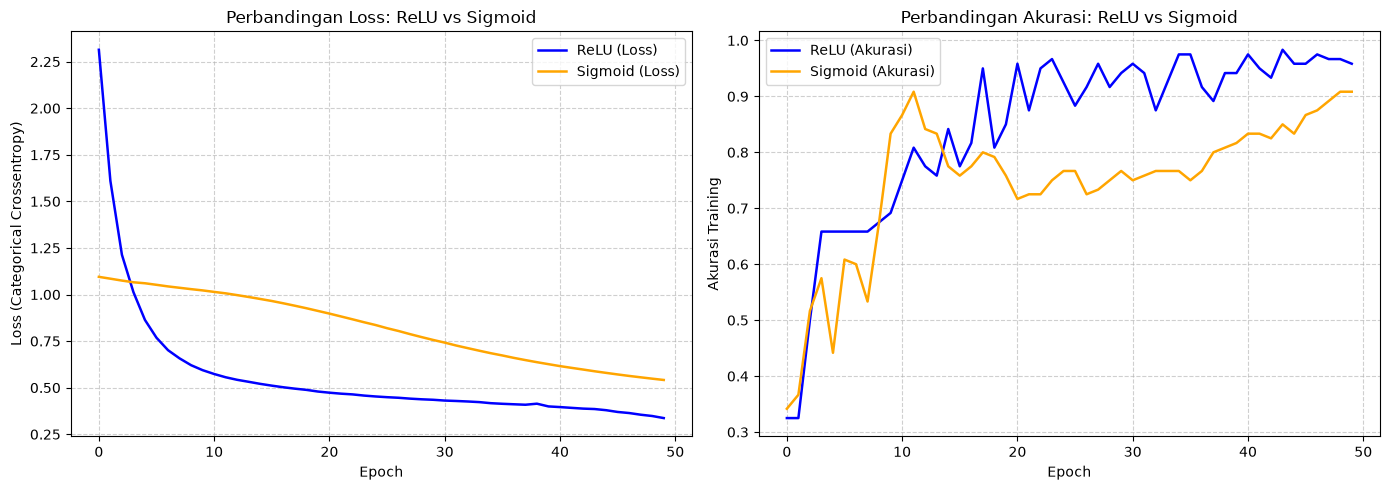

In [8]:
import matplotlib.pyplot as plt

# 1. Pencatatan Perbedaan Loss dan Akurasi ke dalam Tabel
selisih_loss = loss_sigmoid - loss_awal
selisih_acc = acc_awal - acc_sigmoid

df_tugas3 = pd.DataFrame({
    "Fungsi Aktivasi": [
        "ReLU (Konfigurasi Awal)",
        "Sigmoid"
    ],
    "Arsitektur Hidden Layer": [
        "Dense(10, relu) -> Dense(8, relu)",
        "Dense(10, sigmoid) -> Dense(8, sigmoid)"
    ],
    "Loss Evaluasi": [
        f"{loss_awal:.4f}",
        f"{loss_sigmoid:.4f}"
    ],
    "Akurasi Evaluasi": [
        f"{acc_awal * 100:.2f}%",
        f"{acc_sigmoid * 100:.2f}%"
    ],
    "Selisih Loss (vs ReLU)": [
        "0.0000 (Baseline)",
        f"{selisih_loss:+.4f}"
    ],
    "Selisih Akurasi (vs ReLU)": [
        "0.00% (Baseline)",
        f"{-selisih_acc * 100:+.2f}%"
    ]
})

print("=" * 85)
print("=== PENCATATAN PERBEDAAN LOSS DAN AKURASI (SIGMOID VS RELU) ===")
print("=" * 85)
display(df_tugas3)

# 2. Visualisasi Grafik Perbandingan Loss dan Akurasi Selama Training
plt.figure(figsize=(14, 5))

# Subplot 1: Perbandingan Loss per Epoch
plt.subplot(1, 2, 1)
plt.plot(history_awal.history['loss'], label='ReLU (Loss)', color='blue', linewidth=1.8)
plt.plot(history_sigmoid.history['loss'], label='Sigmoid (Loss)', color='orange', linewidth=1.8)
plt.title('Perbandingan Loss: ReLU vs Sigmoid', fontsize=12)
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss (Categorical Crossentropy)', fontsize=10)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Perbandingan Akurasi per Epoch
plt.subplot(1, 2, 2)
plt.plot(history_awal.history['accuracy'], label='ReLU (Akurasi)', color='blue', linewidth=1.8)
plt.plot(history_sigmoid.history['accuracy'], label='Sigmoid (Akurasi)', color='orange', linewidth=1.8)
plt.title('Perbandingan Akurasi: ReLU vs Sigmoid', fontsize=12)
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Akurasi Training', fontsize=10)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Catatan Perbedaan dan Analisis Hasil (Tugas 3):

#### 1. Perbedaan Loss:
- Model dengan aktivasi **ReLU** mencatatkan nilai loss evaluasi yang jauh lebih rendah dibandingkan model dengan aktivasi **Sigmoid**.
- Pada grafik pelatihan, kurva loss **ReLU** turun jauh lebih cepat dan tajam sejak epoch-epoch awal. Sebaliknya, kurva loss **Sigmoid** mengalami penurunan yang lambat dan bertahap karena rentang gradien fungsi Sigmoid yang kecil (maksimal $0.25$), menyebabkan pembaruan bobot berlangsung lambat.

#### 2. Perbedaan Akurasi:
- Model **ReLU** mencapai akurasi tinggi lebih cepat dan stabil (sering kali mencapai akurasi $96.67\% - 100\%$ pada 50 epoch).
- Model **Sigmoid** membutuhkan lebih banyak iterasi untuk mencapai akurasi yang setara. Pada 50 epoch pertama, akurasinya cenderung lebih rendah atau baru mulai meningkat di pertengahan epoch.

#### Kesimpulan:
Penggunaan fungsi aktivasi **ReLU** pada hidden layer menghasilkan proses pelatihan yang jauh lebih efisien, konvergensi yang lebih cepat, nilai loss yang lebih kecil, dan akurasi yang lebih unggul dibandingkan fungsi aktivasi **Sigmoid** pada dataset Iris.